In [124]:
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn 
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [125]:
class Model(nn.Module):
    def __init__(self, inp_l = 13, h1 = 20, h2 = 12, out_l = 3):
        super().__init__()
        self.fc1 = nn.Linear(inp_l, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_l)
        
    def forward(self, x):
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        x = self.out(x)
        return x        

In [126]:
class WineDataset(Dataset):
    def __init__(self):
        # data loading
        xy = np.loadtxt('./wine.csv', delimiter=',', skiprows=1, dtype=np.float32)
        self.x = torch.Tensor(xy[:, 1:])
        self.y = torch.tensor(xy[:, 0]-1, dtype=torch.long)
        self.n_samples = xy.shape[0]
    
        
    def __getitem__(self, index):
        # dataset[0]
        return self.x[index], self.y[index]
        
    def __len__(self):
        # len of dataset
        return self.n_samples
    
dataset = WineDataset()
first_x, first_y = dataset.__getitem__(0)
print(first_x)
print(first_y)

dataloader = DataLoader(dataset=dataset, batch_size=4, shuffle=True)

tensor([1.4230e+01, 1.7100e+00, 2.4300e+00, 1.5600e+01, 1.2700e+02, 2.8000e+00,
        3.0600e+00, 2.8000e-01, 2.2900e+00, 5.6400e+00, 1.0400e+00, 3.9200e+00,
        1.0650e+03])
tensor(0)


Epoch 1/10, Loss = 278.0847
Epoch 2/10, Loss = 1.0956
Epoch 3/10, Loss = 1.0945
Epoch 4/10, Loss = 1.0910
Epoch 5/10, Loss = 1.0932
Epoch 6/10, Loss = 1.0908
Epoch 7/10, Loss = 1.0952
Epoch 8/10, Loss = 1.0937
Epoch 9/10, Loss = 1.0915
Epoch 10/10, Loss = 1.0923


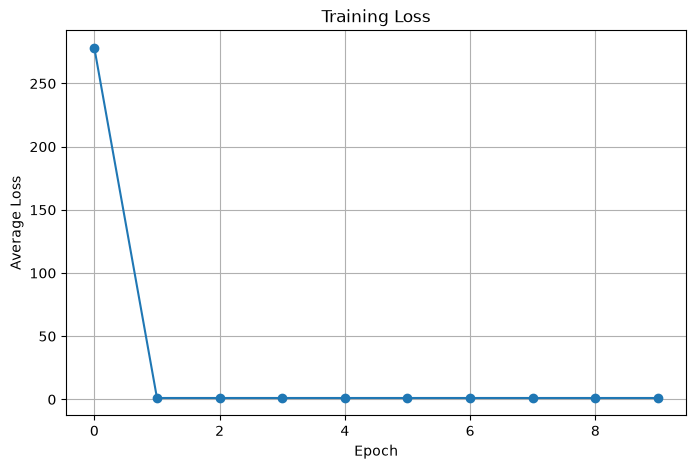

In [127]:
model = Model()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1
)

num_epoch = 10

losses = []

for epoch in range(num_epoch):

    epoch_loss = 0

    for features, target in dataloader:

        outputs = model(features)

        loss = criterion(outputs, target)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()

    # Средний loss за эпоху
    epoch_loss /= len(dataloader)

    losses.append(epoch_loss)

    print(f"Epoch {epoch+1}/{num_epoch}, Loss = {epoch_loss:.4f}")
    
plt.figure(figsize=(8,5))

plt.plot(losses, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.title("Training Loss")

plt.grid(True)

plt.show()

In [128]:
print(model)
for name, param in model.named_parameters():
    print(name)
    print(param.shape)

Model(
  (fc1): Linear(in_features=13, out_features=20, bias=True)
  (fc2): Linear(in_features=20, out_features=12, bias=True)
  (out): Linear(in_features=12, out_features=3, bias=True)
)
fc1.weight
torch.Size([20, 13])
fc1.bias
torch.Size([20])
fc2.weight
torch.Size([12, 20])
fc2.bias
torch.Size([12])
out.weight
torch.Size([3, 12])
out.bias
torch.Size([3])


In [129]:
correct = 0
total = 0

model.eval()

with torch.no_grad():
    for features, labels in dataloader:

        outputs = model(features)

        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f'Accuracy: {accuracy:.2f}%')

Accuracy: 39.89%
